In [1]:
import time
import requests
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

In [22]:
species = ['Cervus canadensis', 'Bouteloua dactyloides']
year = 2025

api = "https://api.gbif.org/v1"
records = []

for name in species:
    response = requests.get(
        f"{api}/species/match",
        params = {'name': name, 'strict': 'true'},
        timeout=60
    )
    response.raise_for_status()
    match = response.json()

    if (
        match.get('matchType') != 'EXACT'
        or match.get('rank') != 'SPECIES'
    ):
        raise ValueError(f'Check the species name: {name}')

    taxon_key = match.get('acceptedUsageKey', match['usageKey'])

    parameters = {
        'taxonKey': taxon_key,
        'country': 'US',
        #'stateProvince': 'Colorado',
        'year': year,
        'basisOfRecord': 'HUMAN_OBSERVATION',
        'occurrenceStatus': 'PRESENT',
        'hasCoordinate': 'true',
        'hasGeospatialIssue': 'false',
        'limit': 300,
        'offset': 0
    }

    species_records = []

    while True:
        response = requests.get(
            f'{api}/occurrence/search',
            params = parameters,
            timeout = 60
        )
        response.raise_for_status()
        page = response.json()

        if page['count'] > 9000:
            raise ValueError(
                f'{name} has too many records for this example. '
                'Narrow the data range or use a GBIF bulk download.'
            )

        for record in page['results']:
            record['queried_species'] = name

        species_records.extend(page['results'])

        if page.get('endOfRecords') or not page['results']:
            break

        parameters['offset'] += len(page['results'])
        time.sleep(0.2)

    records.extend(species_records)
    print(f'{name}: {len(species_records):,} records')

Cervus canadensis: 5,494 records
Bouteloua dactyloides: 846 records


In [23]:
data = pd.DataFrame(records)
data = data[["queried_species", "decimalLongitude", "decimalLatitude"]]
data.head()

,queried_species,decimalLongitude,decimalLatitude
0,Cervus canadensis,-122.966408,38.040772
1,Cervus canadensis,-124.012484,41.377601
2,Cervus canadensis,-103.814588,42.736486
3,Cervus canadensis,-123.903458,43.998438
4,Cervus canadensis,-111.643424,40.069255


<Axes: >

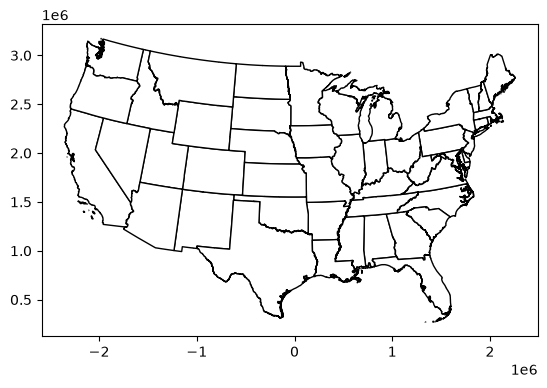

In [38]:
base_url = "https://www2.census.gov/geo/tiger/GENZ2024/shp/"
county_url = "cb_2024_us_county_500k.zip"
state_url = "cb_2024_us_state_500k.zip"

states = gpd.read_file(base_url+state_url)
contiguous_us = states.loc[
    ~states["STUSPS"].isin(["AK", "HI", "PR", "VI", "GU", "MP", "AS"])
]
contiguous_us = contiguous_us.to_crs(epsg=5070)
contiguous_us.plot(edgecolor="black", facecolor="white")
#CO_boundary = states.loc[states['STUSPS'].isin(['CO'])]

#CO_boundary = CO_boundary.to_crs(epsg=2232)
#CO_boundary.plot(edgecolor="black", facecolor="white")


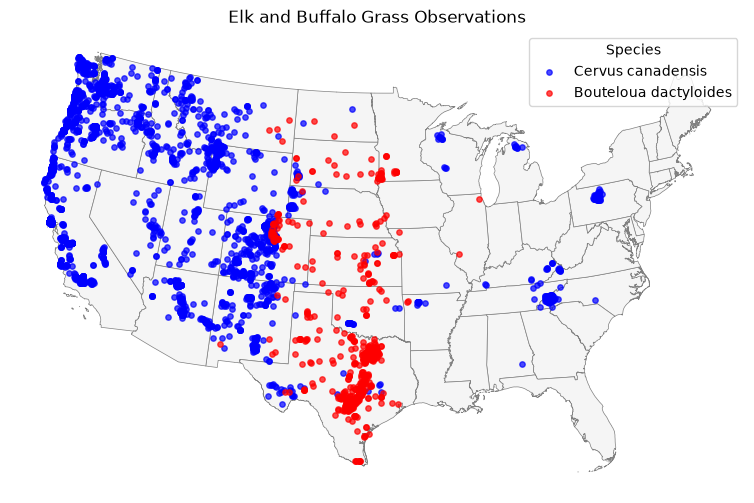

In [39]:
data_points = gpd.GeoDataFrame(
    data.copy(),
    geometry=gpd.points_from_xy(
        data['decimalLongitude'],
        data['decimalLatitude']
    ),
    #crs='EPSG: 2232'
    crs='EPSG:4326'
)

#data_points = data_points.to_crs(epsg=2232)
data_points = data_points.to_crs(epsg=5070)

fig, ax = plt.subplots(figsize=(12, 6))
#CO_boundary.plot(
contiguous_us.plot(
    ax=ax,
    facecolor='whitesmoke',
    edgecolor='gray',
    linewidth=0.5
)

colors = {'Cervus canadensis': 'blue', 'Bouteloua dactyloides': 'red'}

for species, color in colors.items():
    data_points.loc[
        data_points['queried_species'] == species
    ].plot(
        ax = ax,
        color = color,
        markersize=15,
        alpha=0.7,
        label=species
    )

ax.set_title('Elk and Buffalo Grass Observations')
ax.legend(title='Species')
ax.set_axis_off()

plt.show()

In [34]:
points_by_state = gpd.sjoin(
    data_points,
    contiguous_us[['NAME', 'geometry']],
    how='inner',
    predicate='within'
).drop(columns='index_right')

points_by_state.head()

,queried_species,decimalLongitude,decimalLatitude,geometry,NAME
0,Cervus canadensis,-122.966408,38.040772,POINT (-2312943.581 1997772.225),California
1,Cervus canadensis,-124.012484,41.377601,POINT (-2291488.652 2381457.828),California
2,Cervus canadensis,-103.814588,42.736486,POINT (-635388.806 2219397.982),Nebraska
3,Cervus canadensis,-123.903458,43.998438,POINT (-2198063.85 2659179.484),Oregon
4,Cervus canadensis,-111.643424,40.069255,POINT (-1316545.905 2003340.934),Utah


In [42]:
counts = (
    points_by_state
    .groupby(["NAME", "queried_species"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["Cervus canadensis", "Bouteloua dactyloides"], fill_value=0)
)

In [40]:
def choroplethMap(ax, contiguous_us, counts):
    # Total observations per state.
    totals = counts.sum(axis=1).rename("total")

    # Join totals to the state polygons.
    state_map = contiguous_us.merge(
        totals,
        left_on="NAME",
        right_index=True,
        how="left"
    )

    # States without records receive zero.
    state_map["total"] = state_map["total"].fillna(0)

    state_map.plot(
        column="total",
        cmap="RdPu", # This color was selected by me not Ai 
        edgecolor="gray",
        linewidth=0.5,
        legend=True,
        legend_kwds={"label": "Number of observation records"},
        ax=ax
    )

    ax.set_title("Mulberry observations by state")
    ax.set_axis_off()

    return ax

def choroplethEqual(ax, contiguous_us, counts):
    totals = counts.sum(axis=1).rename("total")

    state_map = contiguous_us.merge(
        totals, left_on="NAME", right_index=True, how="left"
    )
    state_map["total"] = state_map["total"].fillna(0)

    state_map.plot(
        column="total",
        scheme="equalinterval",
        k=5,
        cmap="RdPu",
        edgecolor="gray",
        linewidth=0.5,
        legend=True,
        legend_kwds={"title": "Observation records", "fontsize": 8},
        ax=ax
    )

    ax.set_title("Equal interval")
    ax.set_axis_off()
    return ax

def choroplethQuantiles(ax, contiguous_us, counts):
    totals = counts.sum(axis=1).rename("total")

    state_map = contiguous_us.merge(
        totals, left_on="NAME", right_index=True, how="left"
    )
    state_map["total"] = state_map["total"].fillna(0)

    state_map.plot(
        column="total",
        scheme="quantiles",
        k=5,
        cmap="RdPu",
        edgecolor="gray",
        linewidth=0.5,
        legend=True,
        legend_kwds={"title": "Observation records", "fontsize": 8},
        ax=ax
    )

    ax.set_title("Quantiles")
    ax.set_axis_off()
    return ax

def choroplethNatural(ax, contiguous_us, counts):
    totals = counts.sum(axis=1).rename("total")

    state_map = contiguous_us.merge(
        totals, left_on="NAME", right_index=True, how="left"
    )
    state_map["total"] = state_map["total"].fillna(0)

    state_map.plot(
        column="total",
        scheme="fisherjenks",
        k=5,
        cmap="RdPu",
        edgecolor="gray",
        linewidth=0.5,
        legend=True,
        legend_kwds={"title": "Observation records", "fontsize": 8},
        ax=ax
    )

    ax.set_title("Natural breaks (Fisher–Jenks)")
    ax.set_axis_off()
    return ax

c:\Users\Darrin\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\geopandas\plotting.py:746: UserWarning: Numba not installed. Using slow pure python version.
  binning = mapclassify.classify(


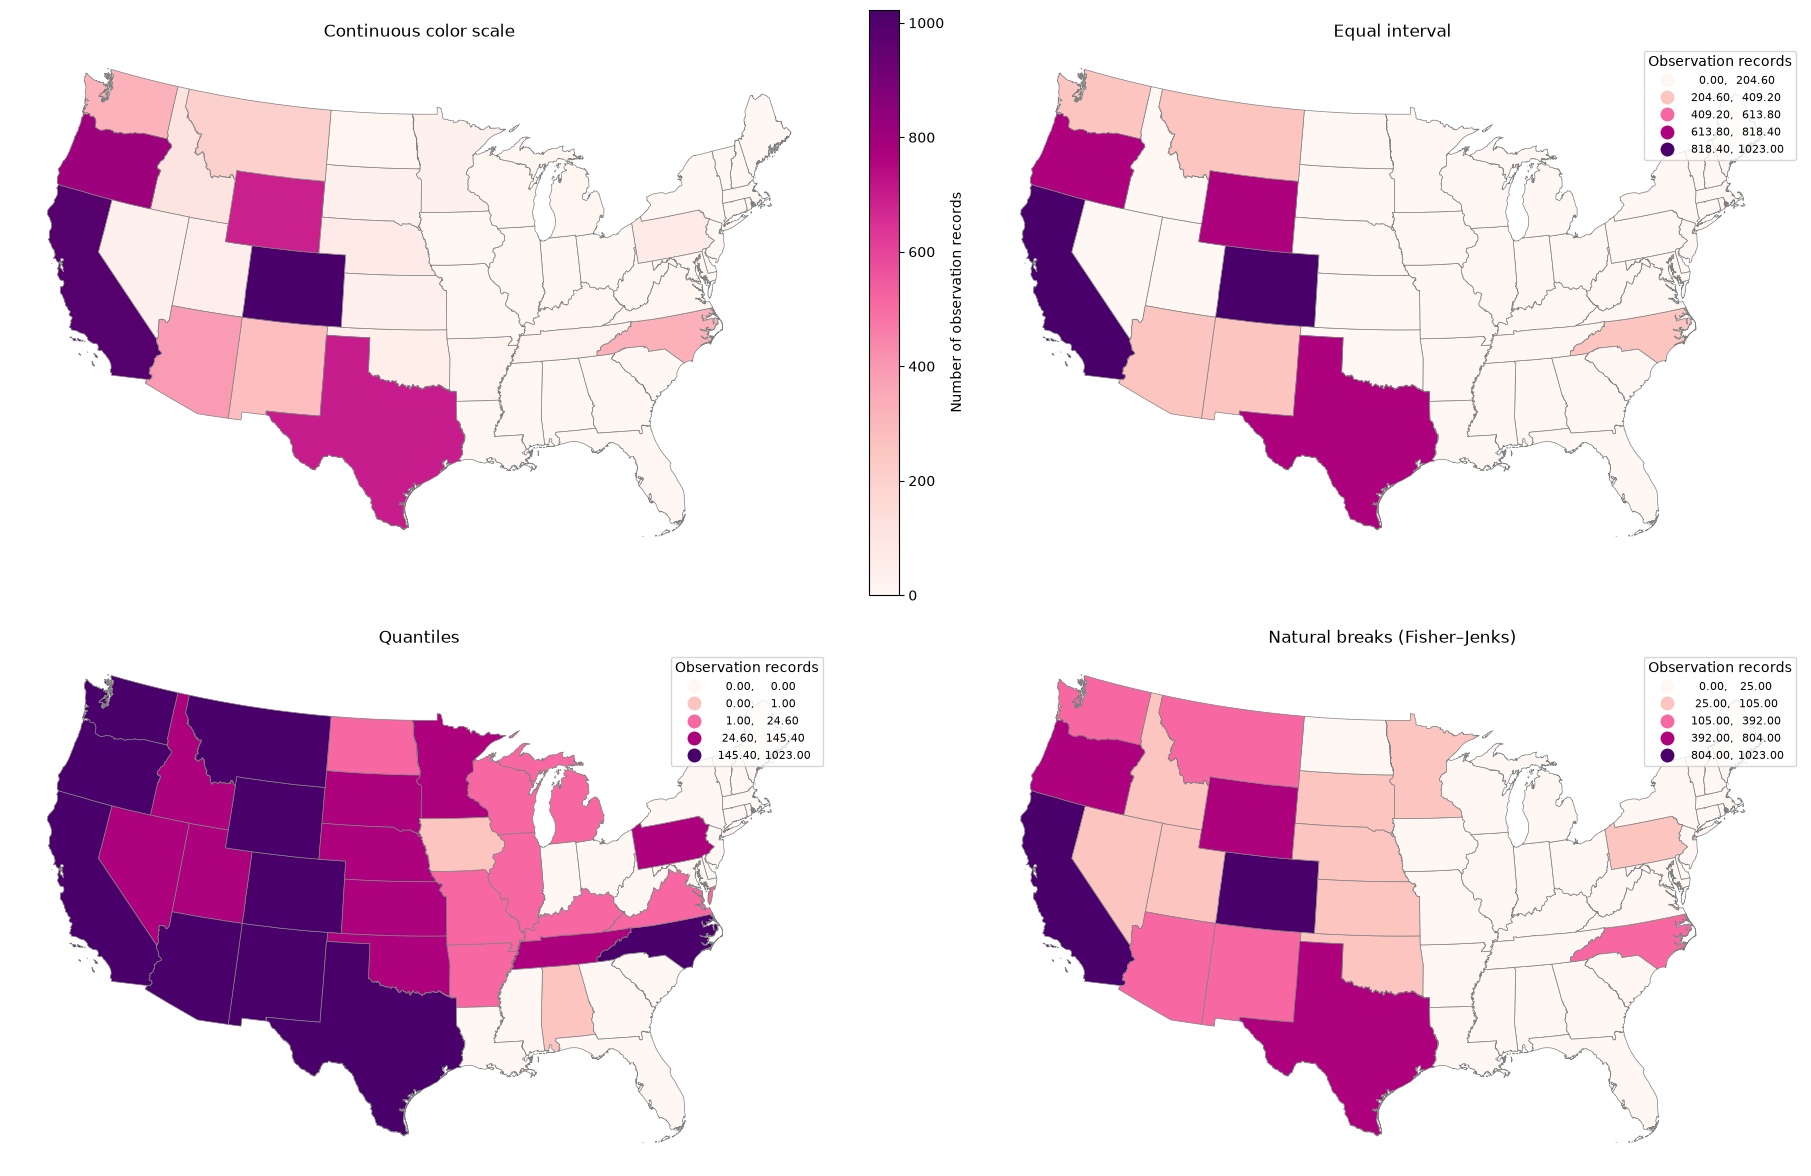

In [43]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 12),
    layout="constrained"
)

choroplethMap(axes[0, 0], contiguous_us, counts)
axes[0, 0].set_title("Continuous color scale")

choroplethEqual(axes[0, 1], contiguous_us, counts)
choroplethQuantiles(axes[1, 0], contiguous_us, counts)
choroplethNatural(axes[1, 1], contiguous_us, counts)

# fig.savefig("mulberry_classification.png", dpi=300, bbox_inches="tight")
# fig.savefig("mulberry_classification.pdf", bbox_inches="tight")

plt.show()

Cervus canadensis positive-count median: 36.0
Bouteloua dactyloides positive-count median: 6.0


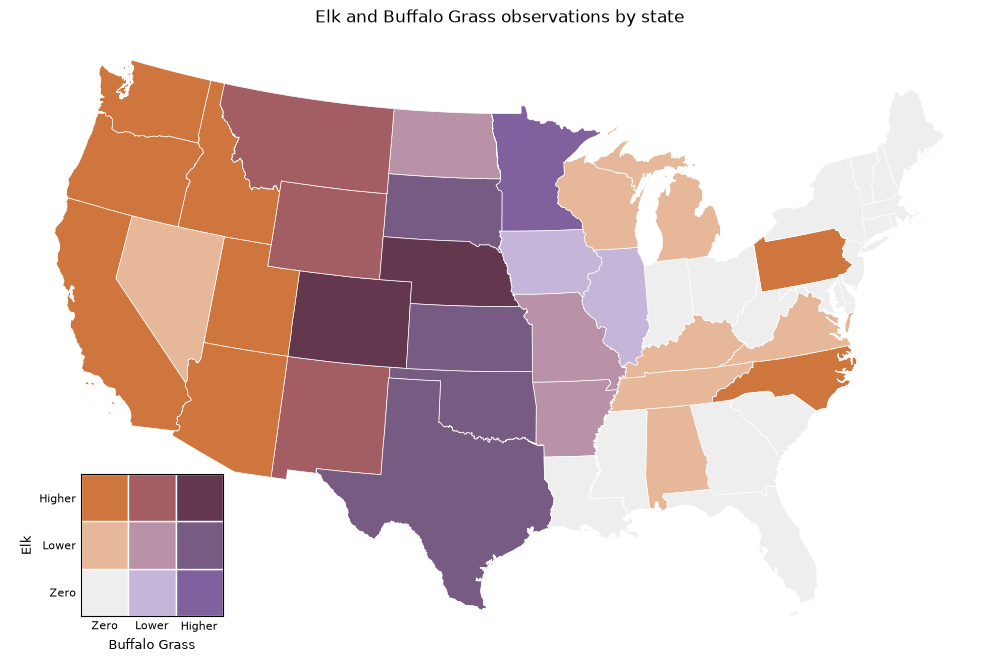

In [48]:
import numpy as np
from matplotlib.patches import Rectangle

# Attach each species' counts to the state polygons.
bivariate = contiguous_us.merge(
    counts,
    left_on="NAME",
    right_index=True,
    how="left"
)

species = ["Cervus canadensis", "Bouteloua dactyloides"]
bivariate[species] = bivariate[species].fillna(0)

# Classify each species:
# 0 = no records
# 1 = positive count at or below the positive-count median
# 2 = count above that median
for name in species:
    values = bivariate[name]
    median = values.loc[values > 0].median()

    bivariate[name + "_class"] = np.select(
        [values == 0, values <= median],
        [0, 1],
        default=2
    )

    print(name, "positive-count median:", median)

# Rows represent increasing red mulberry counts.
# Columns represent increasing white mulberry counts.
palette = np.array([
    ["#eeeeee", "#c5b5d8", "#80619e"],
    ["#e6b899", "#b992a8", "#785b82"],
    ["#cf763e", "#a35e63", "#63384f"]
])

bivariate["color"] = [
    palette[red, white]
    for red, white in zip(
        bivariate["Cervus canadensis_class"],
        bivariate["Bouteloua dactyloides_class"]
    )
]

fig, ax = plt.subplots(figsize=(13, 8))

bivariate.plot(
    color=bivariate["color"],
    edgecolor="white",
    linewidth=0.5,
    ax=ax
)

ax.set_title("Elk and Buffalo Grass observations by state")
ax.set_axis_off()

# Add a 3 × 3 bivariate legend.
legend_ax = ax.inset_axes([0.05, 0.05, 0.19, 0.23])

for red in range(3):
    for white in range(3):
        legend_ax.add_patch(
            Rectangle(
                (white, red), 1, 1,
                facecolor=palette[red, white],
                edgecolor="white"
            )
        )

legend_ax.set_xlim(0, 3)
legend_ax.set_ylim(0, 3)
legend_ax.set_aspect("equal")

legend_ax.set_xticks([0.5, 1.5, 2.5])
legend_ax.set_yticks([0.5, 1.5, 2.5])
legend_ax.set_xticklabels(["Zero", "Lower", "Higher"], fontsize=8)
legend_ax.set_yticklabels(["Zero", "Lower", "Higher"], fontsize=8)

legend_ax.set_xlabel("Buffalo Grass", fontsize=9)
legend_ax.set_ylabel("Elk", fontsize=9)
legend_ax.tick_params(length=0)

plt.show()

Classification schemes can be useful for presenting data to be able to communicate it properly. A good thing about them is that the allow clear communication about the results that were found. A downside to this could be that it takes time to figure out the best way to present the data for a larger audience while keeping the data intact. 